Specificity: Computes the Kalman filter on IV. It also does training on quotes and testing on trades. Results+evaluations plotted. 

In [2]:
import os
import sys
from datetime import date, datetime

# import torch
# from torch.func import jacrev
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import polars as pl
import polars.selectors as cs
import pytz

project_root = os.path.abspath("/Users/elie/Documents/GitHub/quant_data/")

if project_root not in sys.path:
    sys.path.insert(0, project_root)


os.environ["QUANTDATA_RAW_DATA"] = "!/quantdata/raw"  # better set these to environment variables
os.environ["QUANTDATA_TRAINING_DATA"] = (
    "!/quantdata/training"  # better set these to environment variables
)
os.environ["QUANTDATA_PROCESSING_DATA"] = (
    "!/quantdata/processing"  # better set these to environment variables
)
os.environ["QUANTDATA_CACHE_MODE"] = "on"  # turns off global cache mode
os.environ["QUANTDATA_TEST_MODE"] = "0"
import importlib as imp

import quantdata as _

imp.reload(_)
import quantdata.biz_calendar as _

imp.reload(_)
import quantdata.massive.client as _

imp.reload(_)
import quantdata.massive.options.contracts as _

imp.reload(_)

from datetime import date

sys.path.insert(
    0, os.path.join(os.path.dirname(os.path.abspath("__file__")), "..", "shared_functions")
)


import arbitrage
import black_scholes
import ekf
import events
from cdxcore.util import fmt_date, fmt_dict
from cdxcore.verbose import Context

import personal.shared_functions.kalman_filters as kalman_filters
import personal.shared_functions.plots as plots
import personal.shared_functions.utils as utils
from personal.shared_functions.iv_evaluation import evaluate_kalman_iv
from quantdata.massive.client import MassiveClient
from quantdata.massive.taq import TAQMatchConfig, match_taq

/Users/elie/Documents/GitHub/quant_data/quantdata/__init__.py:212: UserWarning: Using cache mode 'on' as specified in environment variable QUANTDATA_CACHE_MODE.


In [3]:
df_tickers = pl.read_csv("../spy_options_tickers.csv")

In [ ]:
trade_date = date(2024, 1, 3)
client = MassiveClient()
df_spy = client.fetch_trades("SPX", trade_date)

In [6]:
# Single call — processes all calls and puts in one batched IV computation.
# is_call column in the output distinguishes the two types.
df_quote_result, df_trade_result = kalman_filters.build_iv_surface(
    df_tickers=df_tickers,
    trade_date=trade_date,
    df_spy=df_spy,
    min_trades=100,
)

O:SPY240105C00469000: dropping 2 bad quotes (crossed×2 (first=2024-01-03 11:49:45.633413-05:00))
O:SPY240105C00472000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 15:51:02.275318-05:00))
O:SPY240105C00473000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:29:17.744517-05:00))
O:SPY240105C00474000: dropping 4 bad quotes (crossed×4 (first=2024-01-03 10:25:56.925706-05:00))
O:SPY240105C00475000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 14:02:06.496803-05:00))
O:SPY240105C00477000: dropping 1 bad quotes (crossed×1 (first=2024-01-03 10:00:44.569057-05:00))
O:SPY240105C00481000: dropping 46 bad quotes (sub-tick bid×46 (first=2024-01-03 16:00:02.443177-05:00))
O:SPY240105C00482000: dropping 64 bad quotes (sub-tick bid×64 (first=2024-01-03 10:00:01.421753-05:00))
O:SPY240105C00483000: dropping 842 bad quotes (sub-tick bid×842 (first=2024-01-03 09:30:00.060278-05:00), zero bid size×1 (first=2024-01-03 09:30:00.060278-05:00))
O:SPY240105C00484000: dropping 2129 bad quotes

In [7]:
df_spy

ts_ns,price,size,trade_code
"datetime[ns, America/New_York]",f64,f64,u32
2024-01-03 04:00:00.023728896 EST,472.04,4.0,73728
2024-01-03 04:00:00.033502208 EST,472.43,16.0,73728
2024-01-03 04:00:00.035570944 EST,472.36,1.0,73728
2024-01-03 04:00:00.035577088 EST,472.31,4.0,73728
2024-01-03 04:00:00.370607616 EST,472.16,2.0,73728
…,…,…,…
2024-01-03 19:59:57.242399488 EST,469.35,100.0,8192
2024-01-03 19:59:57.242399488 EST,469.35,400.0,8192
2024-01-03 19:59:58.998797568 EST,469.355,1.0,73728


In [8]:
df_quote_result

ts_ns,observed_iv,bid_iv,ask_iv,kalman_iv,bid_price,ask_price,forward,discount_factor,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.006736128 EST,0.140982,0.138439,0.143359,0.140982,0.04,0.05,470.43,1.0,0.045034,481.0,true
2024-01-03 09:30:00.006781440 EST,0.13695,0.134075,0.139497,0.13695,0.09,0.11,470.43,1.0,0.100363,479.0,true
2024-01-03 09:30:00.007484160 EST,0.143359,0.132705,0.15164,0.141236,0.03,0.07,470.43,1.0,0.045551,481.0,true
2024-01-03 09:30:00.008294144 EST,0.127732,0.126371,0.129092,0.127732,2.17,2.21,470.43,1.0,2.189967,471.0,false
2024-01-03 09:30:00.008340992 EST,0.138195,0.131123,0.144509,0.137211,0.08,0.13,470.43,1.0,0.101328,479.0,true
…,…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:59.881741568 EST,0.145804,0.145401,0.146126,0.145803,1.88,1.89,468.74,1.0,1.88553,469.0,true
2024-01-03 16:14:59.884593152 EST,0.091882,0.07433,0.104474,0.093966,5.28,5.38,468.74,1.0,5.334368,474.0,false
2024-01-03 16:14:59.884598272 EST,0.110311,0.108205,0.114425,0.110651,3.66,3.72,468.74,1.0,3.68344,472.0,false


In [ ]:
# # forward/discount factor checks
# df_quote_result["discount_factor"].describe()
# plt.hist(df_quote_result["discount_factor"], bins=50)
# df_quote_result["forward"].is_null().sum()
# df_quote_result["discount_factor"].is_null().sum()

statistic,value
str,f64
"""count""",2.193169e6
"""null_count""",0.0
"""mean""",1.0
"""std""",0.0
"""min""",1.0
"""25%""",1.0
"""50%""",1.0
"""75%""",1.0
"""max""",1.0


In [14]:
df_trade_result

ts_ns,observed_iv,bid_iv,ask_iv,bid_price,ask_price,kalman_matched,trade_residual,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.031 EST,0.130745,0.130745,0.1441,0.08,0.13,0.137318,-0.006573,0.103182,479.0,true
2024-01-03 09:30:00.051 EST,0.142976,0.139489,0.142976,0.07,0.08,0.139871,0.003105,0.071086,480.0,true
2024-01-03 09:30:00.059 EST,0.153329,0.01,0.1651,0.0,0.05,null,null,NaN,483.0,true
2024-01-03 09:30:00.102 EST,0.154323,0.149303,0.151009,0.22,0.23,0.150646,0.003677,0.227992,463.0,false
2024-01-03 09:30:00.102 EST,0.141628,0.141628,0.143618,0.57,0.59,0.141883,-0.000255,0.572613,466.0,false
…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,0.128923,0.128139,0.128923,1.03,1.04,0.12846,0.000463,1.034098,467.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false


In [15]:
df_trade_result = df_trade_result.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
print(f"{df_trade_result.shape[0]:,} rows with no nulls / NaNs out of {df_trade_result.shape[0]:,}")

74,410 rows with no nulls / NaNs out of 74,410


In [ ]:
df_trade_result.select(
    pl.col("trade_residual") ** 2
).mean() * 100000  # multiplicator just for better readability of the number

trade_residual
f64
0.602972


## Quptes smile

In [55]:
import personal.shared_functions.utils as _u

df_iv_surface_long = df_quote_result
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

strikes_all = sorted(df_iv_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_iv_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_iv_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered["ts_ns"][row_idx]
row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_iv_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"kalman_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_iv_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"IV smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [56]:
row

ts_ns,bid_iv_450_P,ask_iv_450_P,kalman_iv_450_P,bid_iv_454_C,ask_iv_454_C,kalman_iv_454_C,bid_iv_458_P,ask_iv_458_P,kalman_iv_458_P,bid_iv_459_P,ask_iv_459_P,kalman_iv_459_P,bid_iv_460_P,ask_iv_460_P,kalman_iv_460_P,bid_iv_461_P,ask_iv_461_P,kalman_iv_461_P,bid_iv_462_P,ask_iv_462_P,kalman_iv_462_P,bid_iv_462_P_right,ask_iv_462_P_right,kalman_iv_462_P_right,bid_iv_463_P,ask_iv_463_P,kalman_iv_463_P,bid_iv_464_P,ask_iv_464_P,kalman_iv_464_P,bid_iv_465_P,ask_iv_465_P,kalman_iv_465_P,bid_iv_465_C,ask_iv_465_C,kalman_iv_465_C,…,kalman_iv_475_P,bid_iv_475_C,ask_iv_475_C,kalman_iv_475_C,bid_iv_476_P,ask_iv_476_P,kalman_iv_476_P,bid_iv_476_C,ask_iv_476_C,kalman_iv_476_C,bid_iv_477_P,ask_iv_477_P,kalman_iv_477_P,bid_iv_477_C,ask_iv_477_C,kalman_iv_477_C,bid_iv_478_C,ask_iv_478_C,kalman_iv_478_C,bid_iv_479_C,ask_iv_479_C,kalman_iv_479_C,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C,bid_iv_481_C,ask_iv_481_C,kalman_iv_481_C,bid_iv_482_C,ask_iv_482_C,kalman_iv_482_C,bid_iv_483_C,ask_iv_483_C,kalman_iv_483_C,bid_iv_484_C,ask_iv_484_C,kalman_iv_484_C
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 12:56:18.293149440 EST,0.233666,0.245539,0.24005,0.248528,0.333378,0.300399,0.168611,0.173582,0.170889,0.161977,0.166245,0.163811,0.156266,0.159629,0.157449,0.150241,0.153098,0.1514,0.14632,0.148619,0.147373,0.143658,0.145705,0.144872,0.141682,0.143509,0.14302,0.139082,0.140541,0.139935,0.137021,0.1382,0.137452,0.165574,0.173537,0.168889,…,0.105237,0.137533,0.138679,0.138141,0.079881,0.113173,0.103343,0.136992,0.13843,0.137872,0.01,0.120369,0.102776,0.137235,0.139075,0.138022,0.136913,0.139535,0.138836,0.138084,0.141427,0.140369,0.141944,0.146305,0.144082,0.14194,0.14801,0.145976,0.144801,0.153163,0.150648,0.160391,0.169535,0.161607,0.15233,0.161041,0.155063


In [57]:
spy_mid = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

otm_strikes = sorted(set(strikes_C) | set(strikes_P))
otm_mid, otm_bid, otm_ask = [], [], []

for k in otm_strikes:
    K_int = int(k)
    has_C = f"kalman_iv_{K_int}_C" in row.columns
    has_P = f"kalman_iv_{K_int}_P" in row.columns

    bid_C = row[f"bid_iv_{K_int}_C"][0] if has_C else None
    ask_C = row[f"ask_iv_{K_int}_C"][0] if has_C else None
    bid_P = row[f"bid_iv_{K_int}_P"][0] if has_P else None
    ask_P = row[f"ask_iv_{K_int}_P"][0] if has_P else None

    if has_C and has_P and None not in (bid_C, ask_C, bid_P, ask_P):
        i_bid = max(bid_C, bid_P)
        i_ask = min(ask_C, ask_P)
        if i_bid <= i_ask:
            # spreads overlap → use intersection
            otm_bid.append(i_bid)
            otm_ask.append(i_ask)
            otm_mid.append((i_bid + i_ask) / 2)
        else:
            # no overlap → use OTM leg
            if k > spy_mid:
                otm_bid.append(bid_C)
                otm_ask.append(ask_C)
                otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
            else:
                otm_bid.append(bid_P)
                otm_ask.append(ask_P)
                otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    elif has_C and None not in (bid_C, ask_C):
        otm_bid.append(bid_C)
        otm_ask.append(ask_C)
        otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
    elif has_P and None not in (bid_P, ask_P):
        otm_bid.append(bid_P)
        otm_ask.append(ask_P)
        otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
    else:
        otm_bid.append(None)
        otm_ask.append(None)
        otm_mid.append(None)

fig = go.Figure()
fig.add_trace(go.Scatter(x=otm_strikes, y=otm_mid, mode="lines+markers", name="OTM kalman mid"))
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_bid, mode="lines", name="OTM bid", line=dict(dash="dot"))
)
fig.add_trace(
    go.Scatter(x=otm_strikes, y=otm_ask, mode="lines", name="OTM ask", line=dict(dash="dot"))
)
fig.add_vline(x=spy_mid, line_dash="dash", line_color="gray", annotation_text=f"SPY={spy_mid:.2f}")
fig.update_layout(
    title=f"OTM IV smile — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

# Check arbitrage some rows

In [58]:
has_C_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_C" in df_filtered.columns}
has_P_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_P" in df_filtered.columns}

for i in range(0, df_filtered.shape[0], 100):
    row = df_filtered[i]
    ts = row["ts_ns"][0]
    tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
    spy_mid = df_spy.filter(pl.col("ts_ns") <= ts)["price"][-1]

    valid_strikes, valid_ivs = [], []
    for k in otm_strikes:
        K_int = int(k)
        has_C = k in has_C_set
        has_P = k in has_P_set

        if has_C and has_P:
            bid_C, ask_C = row[f"bid_iv_{K_int}_C"][0], row[f"ask_iv_{K_int}_C"][0]
            bid_P, ask_P = row[f"bid_iv_{K_int}_P"][0], row[f"ask_iv_{K_int}_P"][0]
            i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
            iv = (
                (i_bid + i_ask) / 2
                if i_bid <= i_ask
                else (
                    row[f"kalman_iv_{K_int}_C"][0]
                    if k > spy_mid
                    else row[f"kalman_iv_{K_int}_P"][0]
                )
            )
        elif has_C:
            iv = row[f"kalman_iv_{K_int}_C"][0]
        elif has_P:
            iv = row[f"kalman_iv_{K_int}_P"][0]
        else:
            continue

        valid_strikes.append(k)
        valid_ivs.append(iv)

    if not arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
        "is_arbitrage_free"
    ]:
        print(f"Arbitrage detected at index {i} (timestamp {ts})")

Using parallelization

In [59]:
# from joblib import Parallel, delayed
# from concurrent.futures import ThreadPoolExecutor

# # Single join_asof instead of a per-row filter on df_spy
# sample_df = df_filtered[::10]
# spy_mids = (
#     sample_df.select("ts_ns")
#     .join_asof(df_spy.sort("ts_ns").select("ts_ns", "price"), on="ts_ns", strategy="backward")[
#         "price"
#     ]
#     .to_list()
# )

# has_C_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_C" in df_filtered.columns}
# has_P_set = {k for k in otm_strikes if f"kalman_iv_{int(k)}_P" in df_filtered.columns}

# # Convert to plain Python once — avoids polars row access inside threads
# rows = sample_df.to_dicts()
# timestamps = sample_df["ts_ns"].to_list()


# def check_snapshot(i, row, ts, spy_mid, expiry, otm_strikes, has_C_set, has_P_set):
#     tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
#     valid_strikes, valid_ivs = [], []
#     for k in otm_strikes:
#         K_int = int(k)
#         has_C, has_P = k in has_C_set, k in has_P_set
#         if has_C and has_P:
#             bid_C, ask_C = row[f"bid_iv_{K_int}_C"], row[f"ask_iv_{K_int}_C"]
#             bid_P, ask_P = row[f"bid_iv_{K_int}_P"], row[f"ask_iv_{K_int}_P"]
#             i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
#             iv = (
#                 (i_bid + i_ask) / 2
#                 if i_bid <= i_ask
#                 else (row[f"kalman_iv_{K_int}_C"] if k > spy_mid else row[f"kalman_iv_{K_int}_P"])
#             )
#         elif has_C:
#             iv = row[f"kalman_iv_{K_int}_C"]
#         elif has_P:
#             iv = row[f"kalman_iv_{K_int}_P"]
#         else:
#             continue
#         valid_strikes.append(k)
#         valid_ivs.append(iv)
#     is_free = arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]
#     return i, ts, is_free


# results = Parallel(n_jobs=-1, backend="loky")(
#     delayed(check_snapshot)(
#         i * 100, rows[i], timestamps[i], spy_mids[i], expiry, otm_strikes, has_C_set, has_P_set
#     )
#     for i in range(len(rows))
# )

# for idx, ts, is_free in results:
#     if not is_free:
#         print(f"Arbitrage detected at index {idx} (timestamp {ts})")


In [60]:
# def check_snapshot(args):
#     i, row, ts, spy_mid = args
#     tte = float((expiry - ts).total_seconds()) / (365.25 * 24 * 3600)
#     valid_strikes, valid_ivs = [], []
#     for k in otm_strikes:
#         K_int = int(k)
#         has_C, has_P = k in has_C_set, k in has_P_set
#         if has_C and has_P:
#             bid_C, ask_C = row[f"bid_iv_{K_int}_C"], row[f"ask_iv_{K_int}_C"]
#             bid_P, ask_P = row[f"bid_iv_{K_int}_P"], row[f"ask_iv_{K_int}_P"]
#             i_bid, i_ask = max(bid_C, bid_P), min(ask_C, ask_P)
#             iv = (
#                 (i_bid + i_ask) / 2
#                 if i_bid <= i_ask
#                 else (row[f"kalman_iv_{K_int}_C"] if k > spy_mid else row[f"kalman_iv_{K_int}_P"])
#             )
#         elif has_C:
#             iv = row[f"kalman_iv_{K_int}_C"]
#         elif has_P:
#             iv = row[f"kalman_iv_{K_int}_P"]
#         else:
#             continue
#         valid_strikes.append(k)
#         valid_ivs.append(iv)
#     is_free = arbitrage.check_butterfly(k=valid_strikes, iv=valid_ivs, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]
#     return i, ts, is_free


# tasks = [(i * 100, rows[i], timestamps[i], spy_mids[i]) for i in range(len(rows))]

# with ThreadPoolExecutor() as executor:
#     for idx, ts, is_free in executor.map(check_snapshot, tasks):
#         if not is_free:
#             print(f"Arbitrage detected at index {idx} (timestamp {ts})")


In [61]:
# for i in range(1, df_filtered.shape[0]):
#     row = df_filtered[i]
#     tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
#     mid_ivs_C = [row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C]
#     if not arbitrage.check_butterfly(k=strikes_C, iv=mid_ivs_C, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]:
#         print(f"Arbitrage detected (calls) at index {i} (timestamp {row['ts_ns'][0]})")
#     mid_ivs_P = [row[f"kalman_iv_{int(k)}_P"][0] for k in strikes_P]
#     if not arbitrage.check_butterfly(k=strikes_P, iv=mid_ivs_P, T=tte, plot=False)[
#         "is_arbitrage_free"
#     ]:
#         print(f"Arbitrage detected (puts) at index {i} (timestamp {row['ts_ns'][0]})")

In [62]:
# with dropping quotes and min_trades = 100

# Arbitrage detected at index 32975500 (timestamp 2024-01-03 10:13:05.893184-05:00)
# Arbitrage detected at index 32975600 (timestamp 2024-01-03 10:13:05.893189-05:00)
# Arbitrage detected at index 32975700 (timestamp 2024-01-03 10:13:05.893235-05:00)
# Arbitrage detected at index 32975800 (timestamp 2024-01-03 10:13:05.893451-05:00)
# Arbitrage detected at index 32975900 (timestamp 2024-01-03 10:13:05.893470-05:00)

# Arbitrage detected (calls) at index 329755 (timestamp 2024-01-03 10:13:05.893184-05:00)
# Arbitrage detected (calls) at index 329756 (timestamp 2024-01-03 10:13:05.893189-05:00)
# Arbitrage detected (calls) at index 329757 (timestamp 2024-01-03 10:13:05.893235-05:00)
# Arbitrage detected (calls) at index 329758 (timestamp 2024-01-03 10:13:05.893451-05:00)
# Arbitrage detected (calls) at index 329759 (timestamp 2024-01-03 10:13:05.893470-05:00)
# Arbitrage detected (calls) at index 1503399 (timestamp 2024-01-03 14:20:23.701259-05:00)
# Arbitrage detected (calls) at index 1738694 (timestamp 2024-01-03 14:49:31.390834-05:00)

example plot

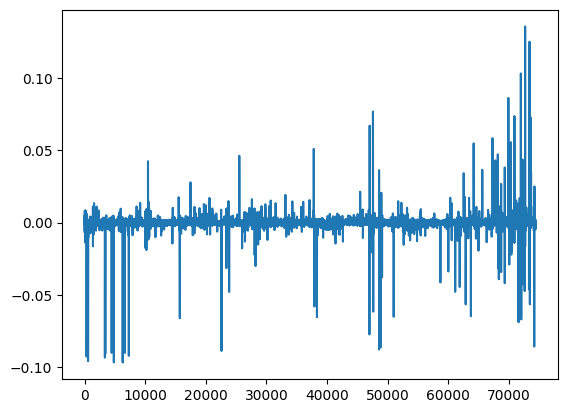

In [64]:
plt.plot(df_trade_result["trade_residual"])

In [65]:
df_trade_result

ts_ns,observed_iv,bid_iv,ask_iv,bid_price,ask_price,kalman_matched,trade_residual,kalman_price,strike,is_call
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,bool
2024-01-03 09:30:00.031 EST,0.130745,0.130745,0.1441,0.08,0.13,0.137318,-0.006573,0.103182,479.0,true
2024-01-03 09:30:00.051 EST,0.142976,0.139489,0.142976,0.07,0.08,0.139871,0.003105,0.071086,480.0,true
2024-01-03 09:30:00.102 EST,0.154323,0.149303,0.151009,0.22,0.23,0.150646,0.003677,0.227992,463.0,false
2024-01-03 09:30:00.102 EST,0.141628,0.141628,0.143618,0.57,0.59,0.141883,-0.000255,0.572613,466.0,false
2024-01-03 09:30:00.111 EST,0.145379,0.140452,0.150292,1.4,1.54,0.145914,-0.000535,1.477615,472.0,true
…,…,…,…,…,…,…,…,…,…,…
2024-01-03 16:14:55.650 EST,0.128923,0.128139,0.128923,1.03,1.04,0.12846,0.000463,1.034098,467.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false
2024-01-03 16:14:56.139 EST,0.126537,0.125065,0.126537,1.38,1.4,0.125703,0.000834,1.388618,468.0,false


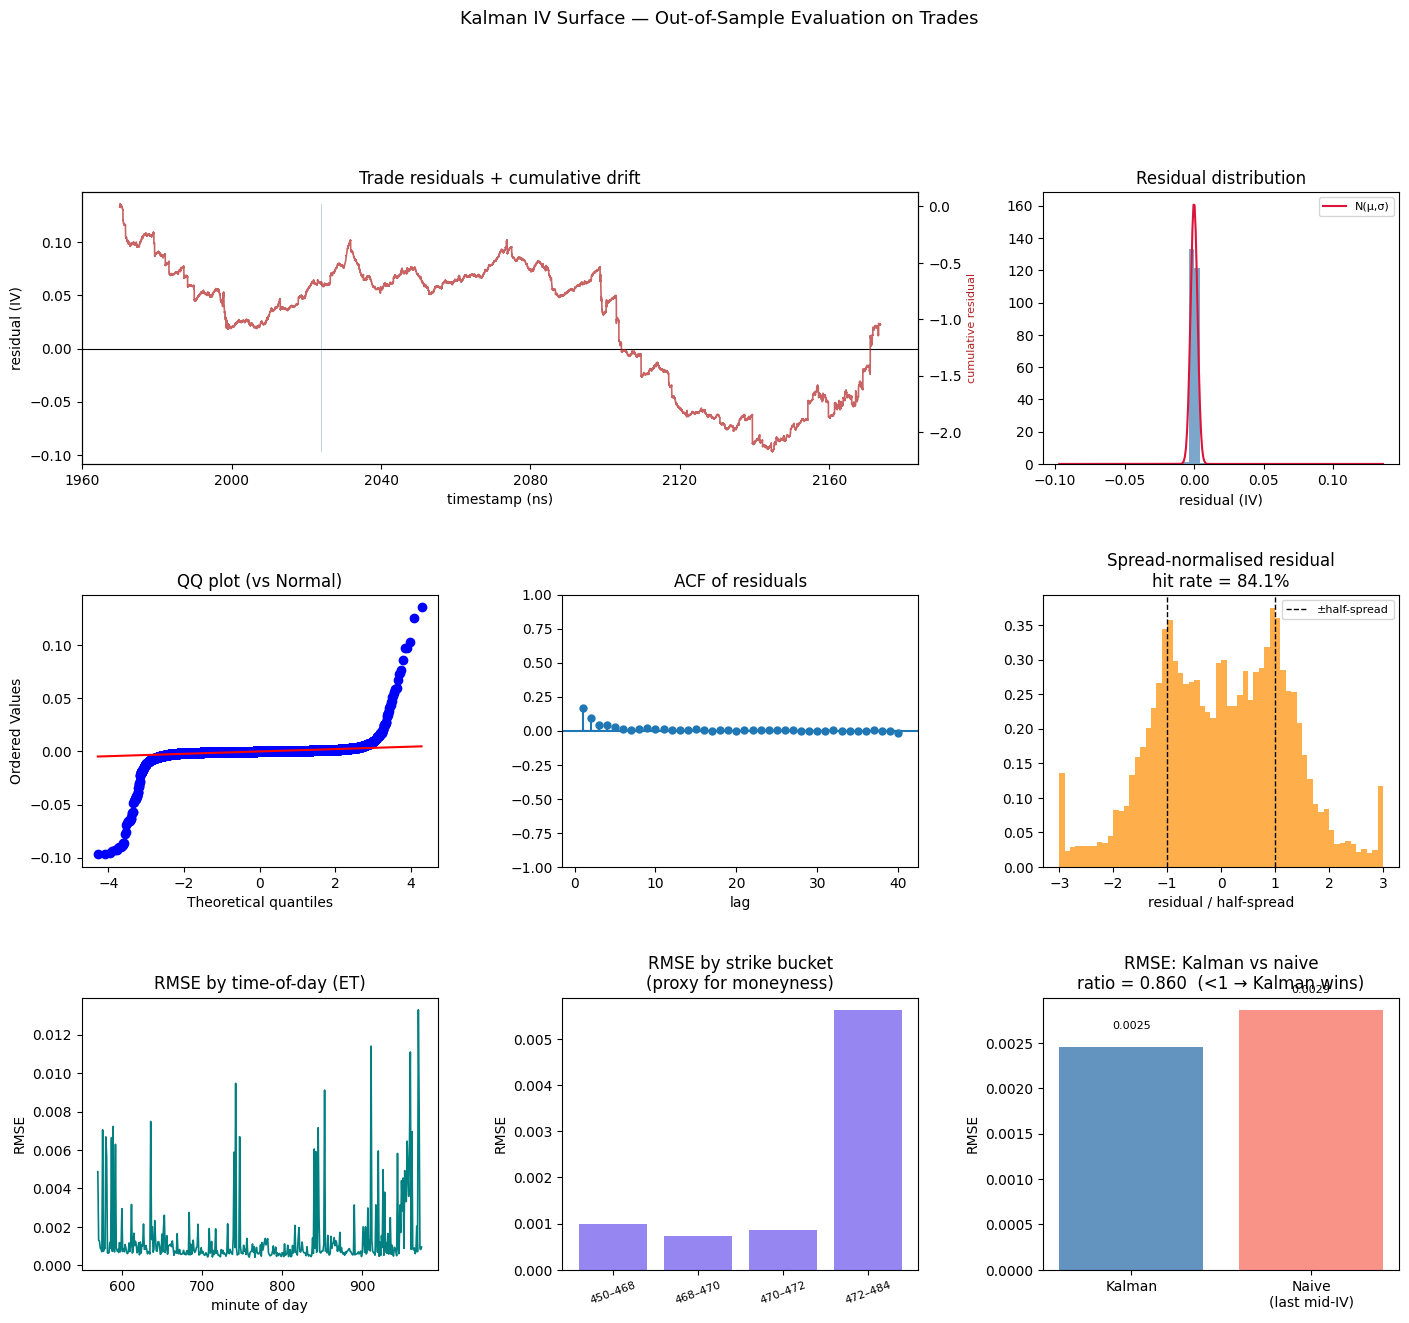

RMSE                 0.00246
MAE                  0.00068
Bias                 -0.00001
Hit rate             84.1%
Naive RMSE           0.00286
RMSE ratio           0.860  (<1 = Kalman beats naive)

Ljung-Box (H0: no autocorrelation in residuals):
        lb_stat  lb_pvalue
10  3113.139054        0.0
20  3139.755089        0.0


In [66]:
metrics = evaluate_kalman_iv(df_quote_result, df_trade_result)

In [67]:
df_price_surface_wide = utils.synchronize_price_surface(
    df_quote_result.rename({"kalman_price": "observed_price"})
)

In [68]:
df_filtered_price = df_price_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)
df_price_surface_long = df_quote_result.rename({"kalman_price": "observed_price"})

strikes_all = sorted(df_price_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_price_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_price_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered_price.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered_price["ts_ns"][row_idx]
row = df_price_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

fig = go.Figure()

fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"observed_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines+markers",
        name="calls — kalman mid",
        line=dict(color="royalblue"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"bid_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — bid",
        line=dict(color="royalblue", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_C,
        y=[row[f"ask_price_{int(k)}_C"][0] for k in strikes_C],
        mode="lines",
        name="calls — ask",
        line=dict(color="royalblue", dash="dot"),
    )
)

fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"observed_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines+markers",
        name="puts — kalman mid",
        line=dict(color="firebrick"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"bid_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — bid",
        line=dict(color="firebrick", dash="dot"),
    )
)
fig.add_trace(
    go.Scatter(
        x=strikes_P,
        y=[row[f"ask_price_{int(k)}_P"][0] for k in strikes_P],
        mode="lines",
        name="puts — ask",
        line=dict(color="firebrick", dash="dot"),
    )
)

fig.update_layout(
    title=f"price smile (calls + puts) — {snapshot_ts}",
    xaxis_title="Strike",
    yaxis_title="Implied Vol",
)
fig.show()

In [69]:
row

ts_ns,bid_price_450_P,ask_price_450_P,observed_price_450_P,bid_price_454_C,ask_price_454_C,observed_price_454_C,bid_price_458_P,ask_price_458_P,observed_price_458_P,bid_price_459_P,ask_price_459_P,observed_price_459_P,bid_price_460_P,ask_price_460_P,observed_price_460_P,bid_price_461_P,ask_price_461_P,observed_price_461_P,bid_price_462_P,ask_price_462_P,observed_price_462_P,bid_price_462_P_right,ask_price_462_P_right,observed_price_462_P_right,bid_price_463_P,ask_price_463_P,observed_price_463_P,bid_price_464_P,ask_price_464_P,observed_price_464_P,bid_price_465_P,ask_price_465_P,observed_price_465_P,bid_price_465_C,ask_price_465_C,observed_price_465_C,…,observed_price_475_P,bid_price_475_C,ask_price_475_C,observed_price_475_C,bid_price_476_P,ask_price_476_P,observed_price_476_P,bid_price_476_C,ask_price_476_C,observed_price_476_C,bid_price_477_P,ask_price_477_P,observed_price_477_P,bid_price_477_C,ask_price_477_C,observed_price_477_C,bid_price_478_C,ask_price_478_C,observed_price_478_C,bid_price_479_C,ask_price_479_C,observed_price_479_C,bid_price_480_C,ask_price_480_C,observed_price_480_C,bid_price_481_C,ask_price_481_C,observed_price_481_C,bid_price_482_C,ask_price_482_C,observed_price_482_C,bid_price_483_C,ask_price_483_C,observed_price_483_C,bid_price_484_C,ask_price_484_C,observed_price_484_C
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 12:56:18.293149440 EST,0.02,0.03,0.025081,16.15,16.5,16.334714,0.05,0.06,0.054472,0.06,0.07,0.064189,0.08,0.09,0.083726,0.1,0.11,0.104027,0.14,0.15,0.144629,0.16,0.17,0.165899,0.19,0.2,0.197375,0.27,0.28,0.275826,0.39,0.4,0.393663,5.67,5.75,5.703124,…,5.148337,0.41,0.42,0.415316,6.0,6.11,6.066115,0.27,0.28,0.276101,6.96,7.08,7.023319,0.18,0.19,0.184287,0.11,0.12,0.117622,0.07,0.08,0.076998,0.05,0.06,0.054773,0.03,0.04,0.036557,0.02,0.03,0.02688,0.02,0.03,0.021232,0.02,0.03,0.022952


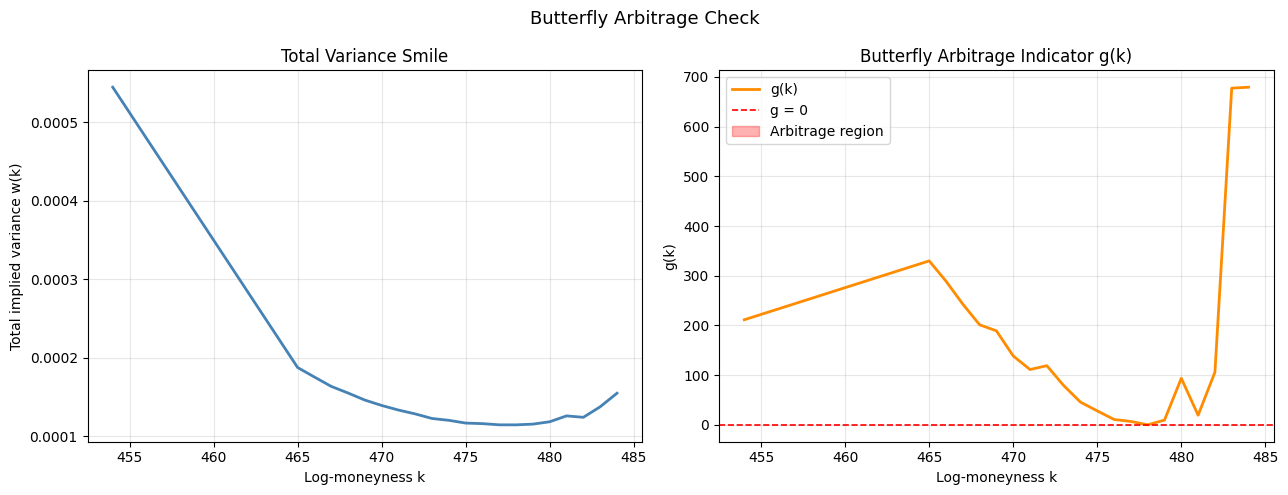

{'is_arbitrage_free': True,
 'min_g': 0.005082815465041165,
 'violations': array([], dtype=float64),
 'g': array([2.11418920e+02, 3.29850729e+02, 2.89097015e+02, 2.42860925e+02,
        2.01297023e+02, 1.89105252e+02, 1.38603880e+02, 1.11235885e+02,
        1.18991441e+02, 7.91634687e+01, 4.57305666e+01, 2.80790797e+01,
        1.07855996e+01, 6.77931559e+00, 5.08281547e-03, 9.61245281e+00,
        9.36726883e+01, 1.93780940e+01, 1.05890719e+02, 6.77386424e+02,
        6.79280755e+02]),
 'w': array([0.0005448 , 0.00018734, 0.00017521, 0.00016327, 0.00015481,
        0.00014582, 0.00013895, 0.00013308, 0.00012816, 0.00012232,
        0.00011999, 0.00011648, 0.00011578, 0.00011426, 0.00011424,
        0.00011515, 0.00011818, 0.00012567, 0.00012383, 0.00013727,
        0.00015455]),
 'k': array([454., 465., 466., 467., 468., 469., 470., 471., 472., 473., 474.,
        475., 476., 477., 478., 479., 480., 481., 482., 483., 484.]),
 'lee_bound_ok': True}

In [87]:
row = df_filtered[21400]
tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
mid_ivs_C = [row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C]
arbitrage.check_butterfly(k=strikes_C, iv=mid_ivs_C, T=tte, plot=True)

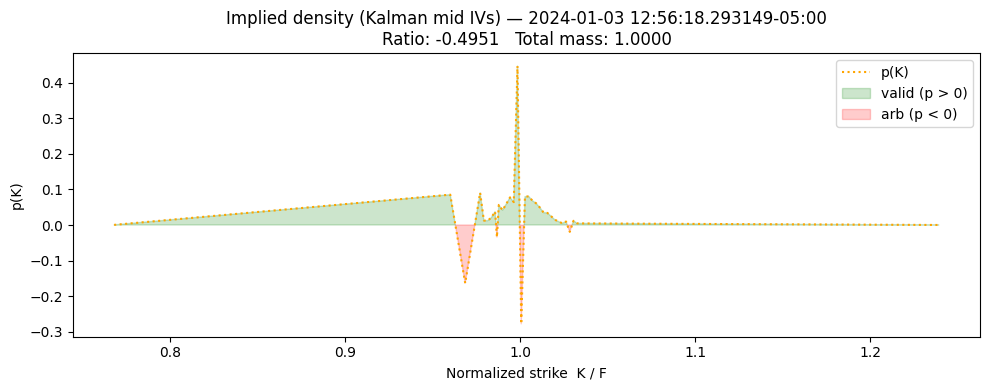

-0.4951129384191764 1.0


In [116]:
# ── Implied probability density from Kalman IVs (Breeden-Litzenberger) ──────
# Depends on: snapshot_ts, expiry, spy_mid, otm_strikes, otm_mid
import scipy.stats as stats


def _bs_call(F, K, T, sigma):
    """Black-Scholes call price with r=0 (forward = spot)."""
    if sigma <= 0 or T <= 0:
        return float(max(F - K, 0.0))
    d1 = (np.log(F / K) + 0.5 * sigma**2 * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return float(F * stats.norm.cdf(d1) - K * stats.norm.cdf(d2))


F = spy_mid  # forward ≈ spot (r=0)
tte = float((expiry - snapshot_ts).total_seconds()) / (365.25 * 24 * 3600)

# Filter strikes with a valid Kalman mid IV
valid = [(k, iv) for k, iv in zip(otm_strikes, otm_mid) if iv is not None]
strikes = np.array([v[0] for v in valid])
ivs = np.array([v[1] for v in valid])

# Normalize to pure space: kappa = K/F, C_pure = C_BS / F
pure_strikes = strikes / F
pure_mids = np.array([_bs_call(F, k, tte, iv) / F for k, iv in zip(strikes, ivs)])

# Extend strike grid with boundary conditions
strikesx = np.zeros(len(pure_strikes) + 2)
strikesx[1:-1] = pure_strikes
strikesx[0] = pure_strikes[0] * 0.8  # far left (deep ITM)
strikesx[-1] = pure_strikes[-1] * 1.2  # far right (deep OTM)

midx = np.zeros_like(strikesx)
midx[1:-1] = pure_mids
midx[0] = 1.0 - strikesx[0]  # deep ITM call ≈ F - K → 1 - kappa
midx[-1] = 0.0  # deep OTM call → 0

# Breeden-Litzenberger: d²C/dK² = risk-neutral density
dCdK = np.diff(midx, prepend=1.0) / np.diff(strikesx, prepend=0.0)
p = np.diff(dCdK, append=0.0)

# Correct approach: compute dC/dK directly, no phantom prepend
dCdK = np.diff(midx) / np.diff(strikesx)

# Left boundary slope = -1 (deep ITM call slope)
# Right boundary slope = 0 (deep OTM call slope)
dCdK_full = np.concatenate([[-1.0], dCdK, [0.0]])

# Second derivative = density
p = np.diff(dCdK_full)


ratio = np.sum(p[p < 0.0])  # negative mass = butterfly arbitrage
total = np.sum(p)  # should be ≈ 1

fig, ax = plt.subplots(figsize=(10, 4))
ax.set_title(
    f"Implied density (Kalman mid IVs) — {snapshot_ts}\nRatio: {ratio:.4f}   Total mass: {total:.4f}"
)
ax.set_xlabel("Normalized strike  K / F")
ax.set_ylabel("p(K)")
ax.plot(strikesx, p, ":", color="orange", label="p(K)")
ax.fill_between(
    strikesx,
    0,
    p,
    where=(p >= 0),
    interpolate=True,
    color="green",
    alpha=0.2,
    label="valid (p > 0)",
)
ax.fill_between(
    strikesx, p, 0, where=(p < 0), interpolate=True, color="red", alpha=0.2, label="arb (p < 0)"
)
# ax.axhline(0, color="purple", linestyle=":")
# ax.axvline(1.0, color="gray", linestyle="--", alpha=0.5, label="ATM (K=F)")
ax.legend()
plt.tight_layout()
plt.show()

print(ratio, total)

In [117]:
print("strikesx:", strikesx[:5], "...", strikesx[-3:])
print("midx:    ", midx[:5], "...", midx[-3:])
print("dCdK_full:", dCdK_full[:5], "...", dCdK_full[-3:])
print("p:        ", p[:5], "...", p[-3:])
print("ratio:", ratio, "total:", total)

strikesx: [0.76803277 0.96004096 0.96857466 0.97710836 0.97924178] ... [1.03044397 1.03257739 1.23909287]
midx:     [0.23196723 0.04002737 0.03222559 0.02302692 0.02092077] ... [2.20584061e-05 1.23053129e-05 0.00000000e+00]
dCdK_full: [-1.         -0.99964415 -0.91423108 -1.07792338 -0.9872151 ] ... [-4.57156737e-03 -5.95854270e-05  0.00000000e+00]
p:         [ 0.00035585  0.08541306 -0.1636923   0.09070828  0.01253487] ... [1.19193280e-02 4.51198194e-03 5.95854270e-05]
ratio: -0.4951129384191764 total: 1.0


In [119]:
print("strikes:", strikes_C[:8])
print("mids:   ", [round(x, 5) for x in midx[:8]])

# Check monotonicity explicitly
for i in range(1, len(midx)):
    if midx[i] >= midx[i - 1]:
        print(
            f"NON-MONOTONE at index {i}: "
            f"C({strikesx[i - 1]})={midx[i - 1]:.5f} "
            f">= C({strikesx[i]})={midx[i]:.5f}"
        )

strikes: [454.0, 465.0, 466.0, 467.0, 468.0, 469.0, 470.0, 471.0]
mids:    [np.float64(0.23197), np.float64(0.04003), np.float64(0.03223), np.float64(0.02303), np.float64(0.02092), np.float64(0.01884), np.float64(0.01679), np.float64(0.01478)]
NON-MONOTONE at index 28: C(1.0261771168903207)=0.00005 >= C(1.02831054124976)=0.00006


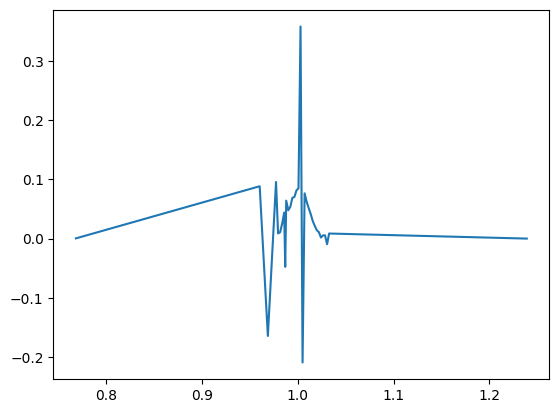

In [91]:
plt.plot(strikesx, p)

In [71]:
df_iv_surface_long = df_quote_result
df_iv_surface_wide = utils.synchronize_iv_surface(df_iv_surface_long)
df_filtered = df_iv_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

strikes_all = sorted(df_iv_surface_long["strike"].unique().to_list())
strikes_C = sorted(df_iv_surface_long.filter(pl.col("is_call"))["strike"].unique().to_list())
strikes_P = sorted(df_iv_surface_long.filter(~pl.col("is_call"))["strike"].unique().to_list())

_, expiry, _ = _u.parse_option_ticker(
    df_tickers.filter(pl.col("ticker").str.contains("C"))["ticker"][0]
)

row_idx = df_filtered.shape[0] // 2  # ← change this (0 to df_filtered.shape[0]-1)
snapshot_ts = df_filtered["ts_ns"][row_idx]
row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)

In [72]:
def extract_otm_details(row_idx, df_filtered, strikes_C, strikes_P):
    snapshot_ts = df_filtered["ts_ns"][row_idx]
    row = df_iv_surface_wide.filter(pl.col("ts_ns") <= snapshot_ts).tail(1)
    spy_mid = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

    otm_strikes = sorted(set(strikes_C) | set(strikes_P))
    otm_mid, otm_bid, otm_ask = [], [], []

    for k in otm_strikes:
        K_int = int(k)
        has_C = f"kalman_iv_{K_int}_C" in row.columns
        has_P = f"kalman_iv_{K_int}_P" in row.columns

        bid_C = row[f"bid_iv_{K_int}_C"][0] if has_C else None
        ask_C = row[f"ask_iv_{K_int}_C"][0] if has_C else None
        bid_P = row[f"bid_iv_{K_int}_P"][0] if has_P else None
        ask_P = row[f"ask_iv_{K_int}_P"][0] if has_P else None

        if has_C and has_P and None not in (bid_C, ask_C, bid_P, ask_P):
            i_bid = max(bid_C, bid_P)
            i_ask = min(ask_C, ask_P)
            if i_bid <= i_ask:
                # spreads overlap → use intersection
                otm_bid.append(i_bid)
                otm_ask.append(i_ask)
                otm_mid.append((i_bid + i_ask) / 2)
            else:
                # no overlap → use OTM leg
                if k > spy_mid:
                    otm_bid.append(bid_C)
                    otm_ask.append(ask_C)
                    otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
                else:
                    otm_bid.append(bid_P)
                    otm_ask.append(ask_P)
                    otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
        elif has_C and None not in (bid_C, ask_C):
            otm_bid.append(bid_C)
            otm_ask.append(ask_C)
            otm_mid.append(row[f"kalman_iv_{K_int}_C"][0])
        elif has_P and None not in (bid_P, ask_P):
            otm_bid.append(bid_P)
            otm_ask.append(ask_P)
            otm_mid.append(row[f"kalman_iv_{K_int}_P"][0])
        else:
            otm_bid.append(None)
            otm_ask.append(None)
            otm_mid.append(None)
    return otm_strikes, otm_mid, otm_bid, otm_ask

In [73]:
def is_arbitrage_row_idx(row_idx, df_filtered, expiry):
    row = df_filtered[row_idx]
    tte = float((expiry - row["ts_ns"])[0].total_seconds()) / (365.25 * 24 * 3600)
    mid_ivs_C = [row[f"kalman_iv_{int(k)}_C"][0] for k in strikes_C]
    return arbitrage.check_butterfly(k=strikes_C, iv=mid_ivs_C, T=tte, plot=False)

In [113]:
def compute_negative_mass_idx(row_idx, df_filtered, df_spy, expiry, otm_strikes, otm_mid):
    snapshot_ts = df_filtered["ts_ns"][row_idx]
    # F = spy_mid because forward ≈ spot (r=0)
    F = df_spy.filter(pl.col("ts_ns") <= snapshot_ts)["price"][-1]

    tte = float((expiry - snapshot_ts).total_seconds()) / (365.25 * 24 * 3600)

    # Filter strikes with a valid Kalman mid IV
    valid = [(k, iv) for k, iv in zip(otm_strikes, otm_mid) if iv is not None]
    strikes = np.array([v[0] for v in valid])
    ivs = np.array([v[1] for v in valid])

    # Normalize to pure space: kappa = K/F, C_pure = C_BS / F
    pure_strikes = strikes / F
    pure_mids = np.array([_bs_call(F, k, tte, iv) / F for k, iv in zip(strikes, ivs)])

    # Extend strike grid with boundary conditions
    strikesx = np.zeros(len(pure_strikes) + 2)
    strikesx[1:-1] = pure_strikes
    strikesx[0] = pure_strikes[0] * 0.8  # far left (deep ITM)
    strikesx[-1] = pure_strikes[-1] * 1.2  # far right (deep OTM)

    midx = np.zeros_like(strikesx)
    midx[1:-1] = pure_mids
    midx[0] = 1.0 - strikesx[0]  # deep ITM call ≈ F - K → 1 - kappa
    midx[-1] = 0.0  # deep OTM call → 0

    # Correct approach: compute dC/dK directly, no phantom prepend
    dCdK = np.diff(midx) / np.diff(strikesx)

    # Left boundary slope = -1 (deep ITM call slope)
    # Right boundary slope = 0 (deep OTM call slope)
    dCdK_full = np.concatenate([[-1.0], dCdK, [0.0]])

    # Second derivative = density
    p = np.diff(dCdK_full)

    # Breeden-Litzenberger: d²C/dK² = risk-neutral density
    # dCdK = np.diff(midx, prepend=1.0) / np.diff(strikesx, prepend=0.0)
    # p = np.diff(dCdK, append=0.0)

    ratio = np.sum(p[p < 0.0])  # negative mass = butterfly arbitrage
    total = np.sum(p)  # should be ≈ 1
    result = {
        "is_arbitrage_free": ratio >= 0.0,
        "negative_mass_ratio": ratio,
        "total_mass": total,
        "density": (strikesx, p),
    }
    return result

In [114]:
res = []
for i in range(0, df_filtered.shape[0], 100000):
    otm_strikes, otm_mid, otm_bid, otm_ask = extract_otm_details(
        i, df_filtered, strikes_C, strikes_P
    )
    result = compute_negative_mass_idx(i, df_filtered, df_spy, expiry, otm_strikes, otm_mid)
    res.append(result["negative_mass_ratio"])

In [115]:
res

[np.float64(-0.3797591510973491),
 np.float64(-0.4216538421123307),
 np.float64(-0.43423317208789525),
 np.float64(-0.4521734279089979),
 np.float64(-0.4097194485786857),
 np.float64(-0.4317013022647894),
 np.float64(-0.41113698164348406),
 np.float64(-0.42652750676275814),
 np.float64(-0.4221491388458235),
 np.float64(-0.418439686952544),
 np.float64(-0.39818327226562583),
 np.float64(-0.40506535914721536),
 np.float64(-0.3950383759432094),
 np.float64(-0.40509497766264496),
 np.float64(-0.38350105443799515),
 np.float64(-0.3887377876946525),
 np.float64(-0.3966578395811474),
 np.float64(-0.35537123645811286),
 np.float64(-0.43082496882012955),
 np.float64(-0.39843262329229995),
 np.float64(-0.43736356754758976),
 np.float64(-0.45823086745929065)]

In [75]:
df_filtered

ts_ns,bid_iv_450_P,ask_iv_450_P,kalman_iv_450_P,bid_iv_454_C,ask_iv_454_C,kalman_iv_454_C,bid_iv_458_P,ask_iv_458_P,kalman_iv_458_P,bid_iv_459_P,ask_iv_459_P,kalman_iv_459_P,bid_iv_460_P,ask_iv_460_P,kalman_iv_460_P,bid_iv_461_P,ask_iv_461_P,kalman_iv_461_P,bid_iv_462_P,ask_iv_462_P,kalman_iv_462_P,bid_iv_462_P_right,ask_iv_462_P_right,kalman_iv_462_P_right,bid_iv_463_P,ask_iv_463_P,kalman_iv_463_P,bid_iv_464_P,ask_iv_464_P,kalman_iv_464_P,bid_iv_465_P,ask_iv_465_P,kalman_iv_465_P,bid_iv_465_C,ask_iv_465_C,kalman_iv_465_C,…,kalman_iv_475_P,bid_iv_475_C,ask_iv_475_C,kalman_iv_475_C,bid_iv_476_P,ask_iv_476_P,kalman_iv_476_P,bid_iv_476_C,ask_iv_476_C,kalman_iv_476_C,bid_iv_477_P,ask_iv_477_P,kalman_iv_477_P,bid_iv_477_C,ask_iv_477_C,kalman_iv_477_C,bid_iv_478_C,ask_iv_478_C,kalman_iv_478_C,bid_iv_479_C,ask_iv_479_C,kalman_iv_479_C,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C,bid_iv_481_C,ask_iv_481_C,kalman_iv_481_C,bid_iv_482_C,ask_iv_482_C,kalman_iv_482_C,bid_iv_483_C,ask_iv_483_C,kalman_iv_483_C,bid_iv_484_C,ask_iv_484_C,kalman_iv_484_C
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2024-01-03 09:30:00.232904704 EST,0.230858,0.251809,0.242527,0.01,0.354156,0.298603,0.173617,0.178065,0.175897,0.165857,0.16973,0.169409,0.160756,0.163908,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.151299,0.153178,0.152445,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.170409,0.181094,0.17549,…,0.114715,0.13777,0.14073,0.138909,0.101494,0.122634,0.111293,0.136819,0.139263,0.138024,0.088748,0.123158,0.104788,0.136279,0.137805,0.13633,0.136856,0.138807,0.137217,0.13647,0.139103,0.138223,0.139489,0.142976,0.139871,0.14307,0.147414,0.143392,0.143069,0.149107,0.144635,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405
2024-01-03 09:30:00.249509376 EST,0.242628,0.251913,0.243165,0.01,0.354156,0.298603,0.173617,0.178065,0.175897,0.165857,0.16973,0.169409,0.160756,0.163908,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.151299,0.153178,0.152445,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.170409,0.181094,0.17549,…,0.114715,0.13777,0.14073,0.138909,0.101494,0.122634,0.111293,0.136819,0.139263,0.138024,0.088748,0.123158,0.104788,0.136279,0.137805,0.13633,0.136856,0.138807,0.137217,0.13647,0.139103,0.138223,0.139489,0.142976,0.139871,0.14307,0.147414,0.143392,0.143069,0.149107,0.144635,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405
2024-01-03 09:30:00.326542848 EST,0.242628,0.251913,0.243165,0.01,0.354156,0.298603,0.173617,0.178065,0.175897,0.165857,0.16973,0.169409,0.160756,0.163908,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.151299,0.153178,0.152445,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.170409,0.181094,0.17549,…,0.114715,0.13777,0.14073,0.138909,0.101494,0.122634,0.111293,0.136819,0.139263,0.138024,0.088748,0.123158,0.104788,0.136279,0.137805,0.13633,0.136856,0.138807,0.137217,0.13647,0.139103,0.138223,0.139489,0.142976,0.139871,0.14307,0.147414,0.143392,0.143069,0.149107,0.144635,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405
2024-01-03 09:30:00.326573312 EST,0.242628,0.251913,0.243165,0.01,0.354156,0.298603,0.173617,0.178065,0.175897,0.165857,0.16973,0.169409,0.160756,0.163908,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.151299,0.153178,0.152445,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.170409,0.181094,0.17549,…,0.114715,0.13777,0.14073,0.138909,0.101494,0.122634,0.111293,0.136819,0.139263,0.138024,0.088748,0.123158,0.104788,0.136279,0.137805,0.13633,0.136856,0.138807,0.137217,0.13647,0.139103,0.138223,0.131696,0.142976,0.137589,0.14307,0

In [100]:
import numpy as np

df_filtered_price = df_price_surface_wide.filter(
    pl.all_horizontal(pl.all().is_not_null()) & pl.all_horizontal(cs.float().is_not_nan())
)

# ── 1. Deduplicate strikes by int representation (column names use int(k)) ────
seen_C, seen_P = set(), set()
strikes_C_dedup, strikes_P_dedup = [], []
for k in strikes_C:
    if int(k) not in seen_C:
        seen_C.add(int(k))
        strikes_C_dedup.append(k)
for k in strikes_P:
    if int(k) not in seen_P:
        seen_P.add(int(k))
        strikes_P_dedup.append(k)

call_cols = [f"observed_price_{int(k)}_C" for k in strikes_C_dedup]
put_cols = [f"observed_price_{int(k)}_P" for k in strikes_P_dedup]

call_prices = df_filtered_price.select(call_cols).to_numpy()  # (n_rows, n_C)
put_prices = df_filtered_price.select(put_cols).to_numpy()  # (n_rows, n_P)


# ── 2. Vectorized Breeden-Litzenberger negative-mass over ALL rows at once ────
def compute_negative_mass(prices_2d: np.ndarray, strikes: list) -> np.ndarray:
    n_rows, _ = prices_2d.shape
    K = np.asarray(strikes, dtype=float)

    ext_K = np.concatenate([[K[0] * 0.8], K, [K[-1] * 1.2]])

    left_bd = 1.0 - ext_K[0]
    ext_prices = np.concatenate(
        [np.full((n_rows, 1), left_bd), prices_2d, np.zeros((n_rows, 1))],
        axis=1,
    )

    d_prices = np.diff(np.concatenate([np.ones((n_rows, 1)), ext_prices], axis=1), axis=1)
    d_K = np.diff(np.concatenate([[0.0], ext_K]))
    dCdK = d_prices / d_K[np.newaxis, :]

    p = np.diff(np.concatenate([dCdK, np.zeros((n_rows, 1))], axis=1), axis=1)

    return np.sum(np.minimum(p, 0.0), axis=1), np.sum(p, axis=1)


# ── 3. Run both legs ──────────────────────────────────────────────────────────
neg_mass_C = compute_negative_mass(call_prices, strikes_C_dedup)  # (n_rows,)
neg_mass_P = compute_negative_mass(put_prices, strikes_P_dedup)  # (n_rows,)

is_arb_C = neg_mass_C[0] < 0
is_arb_P = neg_mass_P[0] < 0  # ie we are discarding the puts here

# ── 4. Attach back to Polars ──────────────────────────────────────────────────
df_filtered_arb = df_filtered.with_columns(
    pl.Series("negative_mass_C", neg_mass_C[0]),
    pl.Series("negative_mass_P", neg_mass_P[0]),
    pl.Series("is_arbitrage_C", is_arb_C),
    pl.Series("is_arbitrage_P", is_arb_P),
)

# ── 5. Row indices where arbitrage is present ─────────────────────────────────
is_arbitrage_row_idx = np.where(is_arb_C | is_arb_P)[0]
print(f"{len(is_arbitrage_row_idx):,} arbitrage rows out of {df_filtered.shape[0]:,}")

2,132,958 arbitrage rows out of 2,132,958


In [103]:
neg_mass_C[1] - 1.0

array([ 2.22044605e-16,  2.22044605e-16,  2.22044605e-16, ...,
       -4.44089210e-16, -4.44089210e-16, -4.44089210e-16],
      shape=(2132958,))

In [77]:
neg_mass_C.min(), neg_mass_C.max(), neg_mass_P.min(), neg_mass_P.max()

(np.float64(-6.280490276201545),
 np.float64(-5.086874901405941),
 np.float64(-6.6882282681288885),
 np.float64(-4.904388221117608))

In [78]:
from datetime import datetime

import numpy as np
import pytz

# ── TTE for every row — vectorized, no Python loop ───────────────────────────
ny_tz = pytz.timezone("America/New_York")
expiry_ns = int(
    ny_tz.localize(datetime(expiry.year, expiry.month, expiry.day, 16, 0)).timestamp() * 1e9
)

ts_ns_arr = df_filtered["ts_ns"].cast(pl.Int64).to_numpy()  # epoch nanoseconds
tte_arr = (expiry_ns - ts_ns_arr) / (365.25 * 24 * 3600 * 1e9)  # (n_rows,)

# ── Extract kalman IVs as 2D numpy ───────────────────────────────────────────
k_arr = np.asarray(strikes_C, dtype=float)
iv_cols = [f"kalman_iv_{int(k)}_C" for k in strikes_C]
iv_2d = df_filtered.select(iv_cols).to_numpy()  # (n_rows, n_C)

# ── Vectorized compute_g across all rows (np.gradient supports 2D) ───────────
w_2d = iv_2d**2 * tte_arr[:, np.newaxis]  # (n_rows, n_C)

w1 = np.gradient(w_2d, k_arr, axis=1)  # dw/dk
w2 = np.gradient(w1, k_arr, axis=1)  # d²w/dk²

g_2d = (
    (1.0 - k_arr * w1 / (2.0 * w_2d)) ** 2  # term1
    - (w1**2 / 4.0) * (1.0 / w_2d + 0.25)  # term2
    + w2 / 2.0  # term3
)  # (n_rows, n_C)

tol = 0.0  # -1e-6
min_g = g_2d.min(axis=1)  # (n_rows,)
d_plus_end = -k_arr[-1] / np.sqrt(w_2d[:, -1]) + np.sqrt(w_2d[:, -1]) / 2.0
lee_ok = d_plus_end < 0  # (n_rows,)

is_arb_iv = (min_g < tol) | ~lee_ok  # True = butterfly arbitrage in IV space

# ── Attach both checks to Polars ──────────────────────────────────────────────
df_filtered_arb = df_filtered_arb.with_columns(
    pl.Series("min_g_C", min_g),
    pl.Series("is_arbitrage_iv_C", is_arb_iv),
    pl.Series("negative_mass_C", neg_mass_C),  # from previous cell
    pl.Series("is_arbitrage_price_C", is_arb_C),  # from previous cell
)

# ── Compare the two ───────────────────────────────────────────────────────────
n = df_filtered.shape[0]
both = (is_arb_iv & is_arb_C).sum()
iv_only = (is_arb_iv & ~is_arb_C).sum()
price_only = (~is_arb_iv & is_arb_C).sum()
neither = (~is_arb_iv & ~is_arb_C).sum()

print(f"Total rows : {n:>10,}")
print(f"Both agree arb   : {both:>10,}  ({100 * both / n:.2f}%)")
print(f"IV only    : {iv_only:>10,}  ({100 * iv_only / n:.2f}%)")
print(f"Price only : {price_only:>10,}  ({100 * price_only / n:.2f}%)")
print(f"Neither    : {neither:>10,}  ({100 * neither / n:.2f}%)")

Total rows :  2,132,958
Both agree arb   :          0  (0.00%)
IV only    :          0  (0.00%)
Price only :  2,132,958  (100.00%)
Neither    :          0  (0.00%)


In [79]:
df_filtered_arb

ts_ns,bid_iv_450_P,ask_iv_450_P,kalman_iv_450_P,bid_iv_454_C,ask_iv_454_C,kalman_iv_454_C,bid_iv_458_P,ask_iv_458_P,kalman_iv_458_P,bid_iv_459_P,ask_iv_459_P,kalman_iv_459_P,bid_iv_460_P,ask_iv_460_P,kalman_iv_460_P,bid_iv_461_P,ask_iv_461_P,kalman_iv_461_P,bid_iv_462_P,ask_iv_462_P,kalman_iv_462_P,bid_iv_462_P_right,ask_iv_462_P_right,kalman_iv_462_P_right,bid_iv_463_P,ask_iv_463_P,kalman_iv_463_P,bid_iv_464_P,ask_iv_464_P,kalman_iv_464_P,bid_iv_465_P,ask_iv_465_P,kalman_iv_465_P,bid_iv_465_C,ask_iv_465_C,kalman_iv_465_C,…,bid_iv_476_C,ask_iv_476_C,kalman_iv_476_C,bid_iv_477_P,ask_iv_477_P,kalman_iv_477_P,bid_iv_477_C,ask_iv_477_C,kalman_iv_477_C,bid_iv_478_C,ask_iv_478_C,kalman_iv_478_C,bid_iv_479_C,ask_iv_479_C,kalman_iv_479_C,bid_iv_480_C,ask_iv_480_C,kalman_iv_480_C,bid_iv_481_C,ask_iv_481_C,kalman_iv_481_C,bid_iv_482_C,ask_iv_482_C,kalman_iv_482_C,bid_iv_483_C,ask_iv_483_C,kalman_iv_483_C,bid_iv_484_C,ask_iv_484_C,kalman_iv_484_C,negative_mass_C,negative_mass_P,is_arbitrage_C,is_arbitrage_P,min_g_C,is_arbitrage_iv_C,is_arbitrage_price_C
"datetime[ns, America/New_York]",f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,bool,bool,f64,bool,bool
2024-01-03 09:30:00.232904704 EST,0.230858,0.251809,0.242527,0.01,0.354156,0.298603,0.173617,0.178065,0.175897,0.165857,0.16973,0.169409,0.160756,0.163908,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.151299,0.153178,0.152445,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.170409,0.181094,0.17549,…,0.136819,0.139263,0.138024,0.088748,0.123158,0.104788,0.136279,0.137805,0.13633,0.136856,0.138807,0.137217,0.13647,0.139103,0.138223,0.139489,0.142976,0.139871,0.14307,0.147414,0.143392,0.143069,0.149107,0.144635,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405,-5.167706,-4.976626,true,false,5.283861,false,true
2024-01-03 09:30:00.249509376 EST,0.242628,0.251913,0.243165,0.01,0.354156,0.298603,0.173617,0.178065,0.175897,0.165857,0.16973,0.169409,0.160756,0.163908,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.151299,0.153178,0.152445,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.170409,0.181094,0.17549,…,0.136819,0.139263,0.138024,0.088748,0.123158,0.104788,0.136279,0.137805,0.13633,0.136856,0.138807,0.137217,0.13647,0.139103,0.138223,0.139489,0.142976,0.139871,0.14307,0.147414,0.143392,0.143069,0.149107,0.144635,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405,-5.167706,-4.976697,true,false,5.283861,false,true
2024-01-03 09:30:00.326542848 EST,0.242628,0.251913,0.243165,0.01,0.354156,0.298603,0.173617,0.178065,0.175897,0.165857,0.16973,0.169409,0.160756,0.163908,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.151299,0.153178,0.152445,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.170409,0.181094,0.17549,…,0.136819,0.139263,0.138024,0.088748,0.123158,0.104788,0.136279,0.137805,0.13633,0.136856,0.138807,0.137217,0.13647,0.139103,0.138223,0.139489,0.142976,0.139871,0.14307,0.147414,0.143392,0.143069,0.149107,0.144635,0.145147,0.15349,0.149482,0.154975,0.163817,0.158405,-5.167706,-4.976697,true,false,5.283861,false,true
2024-01-03 09:30:00.326573312 EST,0.242628,0.251913,0.243165,0.01,0.354156,0.298603,0.173617,0.178065,0.175897,0.165857,0.16973,0.169409,0.160756,0.163908,0.163651,0.156516,0.159098,0.157883,0.152496,0.154547,0.154141,0.151299,0.153178,0.152445,0.149082,0.150786,0.150646,0.147237,0.148611,0.147927,0.143565,0.145845,0.14471,0.170409,0.181094,0.17549,…,0.136819,0.139263,0.138024,0.088748,0.123158,0.104788,0.136279,0.137805,0.13633,0.136856,0.138807,0.137217,0.13647,0.139103,0.138223,0.131696,0.142976,0.137589,0.14307,0.147414,0.143392,0.143069,0.149107,0.144635,0.145147,0.15349,0.149482,0.154975

In [80]:
df_filtered_arb.filter(pl.col("is_arbitrage_iv_C") == True).select(pl.col("min_g_C")).describe()

statistic,min_g_C
str,f64
"""count""",0.0
"""null_count""",0.0
"""mean""",null
"""std""",null
"""min""",null
"""25%""",null
"""50%""",null
"""75%""",null
"""max""",null


In [81]:
df_filtered_arb.select(pl.col("is_arbitrage_iv_C") == True)

is_arbitrage_iv_C
bool
false
false
false
false
false
…
false
false
false


In [82]:
# to be tested

In [83]:
# run over all rows, see how many disagree/agree.

In [84]:
strikesx

array([0.76803277, 0.96004096, 0.96857466, 0.97710836, 0.97924178,
       0.98137521, 0.98350863, 0.98564205, 0.98670877, 0.98777548,
       0.9899089 , 0.99204233, 0.99417575, 0.99630918, 0.9984426 ,
       1.00057602, 1.00270945, 1.00484287, 1.0069763 , 1.00910972,
       1.01124315, 1.01337657, 1.01551   , 1.01764342, 1.01977684,
       1.02191027, 1.02404369, 1.02617712, 1.02831054, 1.03044397,
       1.03257739, 1.23909287])

In [85]:
ratio, total

(np.float64(-0.43017442778701653), np.float64(1.0))

In [86]:
# import re


# def extract_prices_from_row(row):
#     pattern = re.compile(r"^(bid_price|ask_price|observed_price)_(\d+)_(C|P)$")

#     calls, puts = {}, {}
#     for col in row.columns:
#         m = pattern.match(col)
#         if not m:
#             continue
#         price_type, strike, cp = m.group(1), int(m.group(2)), m.group(3)
#         d = calls if cp == "C" else puts
#         d.setdefault(strike, {})[price_type] = row[col][0]

#     strikes_C = sorted(calls)
#     strikes_P = sorted(puts)

#     bid_C = [calls[k].get("bid_price") for k in strikes_C]
#     ask_C = [calls[k].get("ask_price") for k in strikes_C]
#     observed_C = [calls[k].get("observed_price") for k in strikes_C]

#     bid_P = [puts[k].get("bid_price") for k in strikes_P]
#     ask_P = [puts[k].get("ask_price") for k in strikes_P]
#     observed_P = [puts[k].get("observed_price") for k in strikes_P]

#     return strikes_C, bid_C, ask_C, observed_C, strikes_P, bid_P, ask_P, observed_P
